# Oil-price changes and consumer inflation across four economies
**Foundations of Data Science — computational report**

Sunidhi Suri (ss21743), Omkar Gadute (org2029), Hriday Badani (hrb9339)

All nine sections below execute against verified local snapshots. Gaussian and Student-t models are
refitted for this report; earlier exploratory CSV estimates are not substituted. Repeated execution can
reuse content-addressed fits keyed to data, model source, priors, seeds and sampler settings.

## 1. Research question and estimand
What is the effect of a 10-percentage-point higher monthly Brent oil-price change on next-month
consumer inflation in the US, China, Japan and Canada, adjusting for prior global economic activity?

Our target is a country-specific one-month continuous-treatment contrast,
$\tau_i(a)=\mathbb{E}[Y_{it}(a+1)-Y_{it}(a)]$. Treatment is measured in units of 10 percentage points
of monthly oil-price change. Under a constant linear effect and the identification assumptions below,
$\tau_i(a)=\beta_i$. Without those assumptions, the regression coefficient remains an association.
Country labels index separate analyses; 1,200 country-month rows do not represent 1,200 independent
oil shocks. No formal between-country causal ranking is assumed.

In [1]:
from pathlib import Path
import sys
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'analysis/data.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from analysis.data import COUNTRIES, FLOWS, prepare_panel
from analysis.model import design

OUT = ROOT/'results/final_project'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 20261124
RNG = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT/(name+'.png'), bbox_inches='tight')
    plt.show()
    plt.close()

environment = pd.DataFrame({'package': ['Python', 'numpy', 'pandas', 'scipy', 'matplotlib', 'arviz'],
                           'version': [platform.python_version()] + [metadata.version(p) for p in
                                       ['numpy','pandas','scipy','matplotlib','arviz']]})
print('Interpreter:', sys.executable)
display(environment)

Interpreter: C:\Users\Omkar\Documents\NYU Projects\FDS Project\.venv\Scripts\python.exe


,package,version
0,Python,3.11.9
1,numpy,2.4.6
2,pandas,3.0.5
3,scipy,1.17.1
4,matplotlib,3.11.2
5,arviz,0.23.4


## 2. Data sources, variables and preparation
Monthly national all-items CPI indices come from OECD: the COICOP 1999 flow for US/China and the
COICOP 2018 flow for Japan/Canada. Every country's index is unadjusted; seasonal structure is modeled
consistently rather than mixing adjusted and unadjusted outcomes. National baskets are not perfectly
harmonized. Brent is nominal USD/barrel (EIA via FRED); IGREA is the Dallas Fed's shipping-based
industrial-commodity activity proxy, not GDP growth.

| Role | Transformation | Units |
|---|---|---|
| Treatment | $T_t=100(P_{t-1}/P_{t-2}-1)/10$ | 10-percentage-point monthly oil change |
| Outcome | $Y_{it}=100(I_{it}/I_{i,t-1}-1)$ | Monthly inflation percentage points, not annualized |
| Potential confounder | $C_t=G_{t-2}/100$ | 100 IGREA index points |

Raw history starts in 1999 so lags precede the January 2000 analysis boundary. All shifts are applied
to an explicit monthly calendar. No interpolation, cross-flow splicing, or automatic downloading is
performed. Source dates are reference months, not publication dates; revised snapshots do not support
a claim of real-time information availability. All hashes and exact URLs are stored in source manifests.

In [2]:
panel, source_audit = prepare_panel(ROOT)
panel.to_csv(ROOT/'data/processed/multicountry_monthly.csv', index=False)
source_audit.to_csv(OUT/'source_verification.csv', index=False)
coverage = panel.groupby('iso3', sort=False).agg(
    country=('country','first'), first_month=('date','min'), last_month=('date','max'),
    observations=('date','size'), inflation_available=('monthly','count'),
    treatment_available=('T','count'), confound_available=('C','count'))
assert coverage.observations.eq(300).all()
assert panel.groupby('date')['T'].nunique().eq(1).all()
assert panel.groupby('date')['C'].nunique().eq(1).all()
coverage.to_csv(OUT/'coverage.csv')
display(source_audit[['file','verified','recorded_retrieval_utc']])
display(coverage)
groups = {iso: panel.loc[panel.iso3.eq(iso)].reset_index(drop=True) for iso in COUNTRIES}
# Check boundary timing against raw source dates independently of row shifts.
oil = pd.read_csv(ROOT/'data/raw/brent_direct.csv', index_col=0, parse_dates=True).iloc[:,0]
activity = pd.read_csv(ROOT/'data/raw/igrea.csv', index_col=0, parse_dates=True).iloc[:,0]
for date in pd.to_datetime(['2000-01-01','2019-12-01','2020-01-01','2024-12-01']):
    observed = panel.loc[(panel.iso3=='USA') & (panel.date==date)].iloc[0]
    previous, before = date-pd.DateOffset(months=1), date-pd.DateOffset(months=2)
    assert np.isclose(observed['T'], 10*(oil.loc[previous]/oil.loc[before]-1))
    assert np.isclose(observed['C'], activity.loc[before]/100)
print('Four complete calendars and pre-treatment lag boundaries verified; no imputation.')

,file,verified,recorded_retrieval_utc
0,brent_direct.csv,True,2026-11-13T23:55:19.575411+00:00
1,igrea.csv,True,2026-11-14T00:06:53.414178+00:00
2,oecd_country_cpi_1999.csv,True,2026-11-14T00:29:34.173855+00:00
3,oecd_country_cpi_2018.csv,True,2026-11-14T00:29:36.588972+00:00


,country,first_month,last_month,observations,inflation_available,treatment_available,confound_available
iso3,,,,,,,
USA,United States,2000-01-01,2024-12-01,300,300,300,300
CHN,China,2000-01-01,2024-12-01,300,300,300,300
JPN,Japan,2000-01-01,2024-12-01,300,300,300,300
CAN,Canada,2000-01-01,2024-12-01,300,300,300,300


Four complete calendars and pre-treatment lag boundaries verified; no imputation.


## 3. Exploratory analysis
We summarize the outcomes separately by country and the shared global predictors only once. This
avoids presenting repeated oil observations as independent measurements. Descriptive lag plots and
seasonal patterns are not causal evidence and do not determine whether an effect must be positive.

,n,minimum,maximum,mean,median,sd
country,,,,,,
Canada,300.0,-1.0372,1.4305,0.1818,0.1873,0.3887
China,300.0,-1.3889,2.6000,0.1671,0.1000,0.6033
Japan,300.0,-0.8028,2.1053,0.0428,0.0000,0.3047
United States,300.0,-1.9153,1.3736,0.2105,0.2015,0.3831


,n,minimum,maximum,mean,median,sd
Brent USD/barrel,300.0,18.3800,132.7200,66.6913,64.5950,28.7733
Oil treatment T,300.0,-4.2580,5.9848,0.0896,0.1966,1.0115
Prior global activity C,300.0,-1.6247,1.8859,0.0754,-0.0139,0.6808


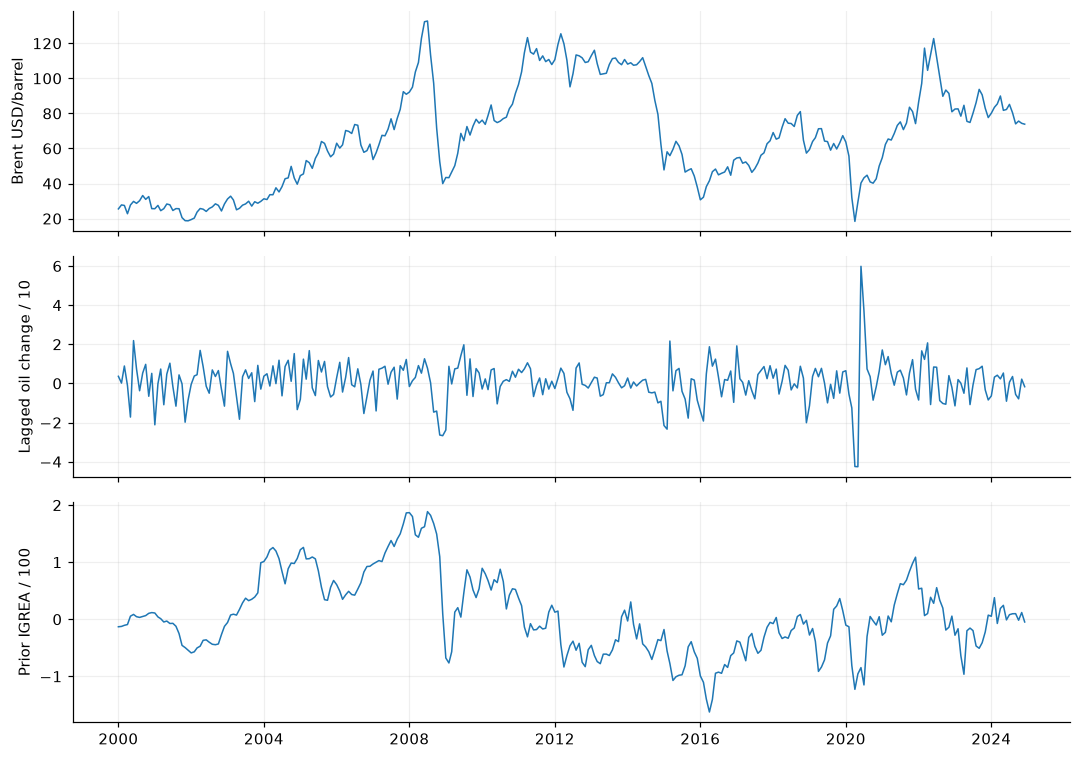

In [3]:
def describe(series):
    return pd.Series({'n':series.count(), 'minimum':series.min(), 'maximum':series.max(),
                      'mean':series.mean(), 'median':series.median(), 'sd':series.std(ddof=1)})

inflation_summary = panel.groupby('country')['monthly'].apply(describe).unstack()
global_summary = pd.DataFrame({name:describe(groups['USA'][column]) for name,column in
                               [('Brent USD/barrel','oil_usd'),('Oil treatment T','T'),('Prior global activity C','C')]}).T
inflation_summary.to_csv(OUT/'inflation_summary.csv')
global_summary.to_csv(OUT/'global_predictor_summary.csv')
display(inflation_summary.round(4))
display(global_summary.round(4))
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, col, label in zip(axes, ['oil_usd','T','C'], ['Brent USD/barrel','Lagged oil change / 10','Prior IGREA / 100']):
    ax.plot(groups['USA'].date, groups['USA'][col], linewidth=1)
    ax.set_ylabel(label); ax.grid(alpha=.2)
save_figure('global_predictors')

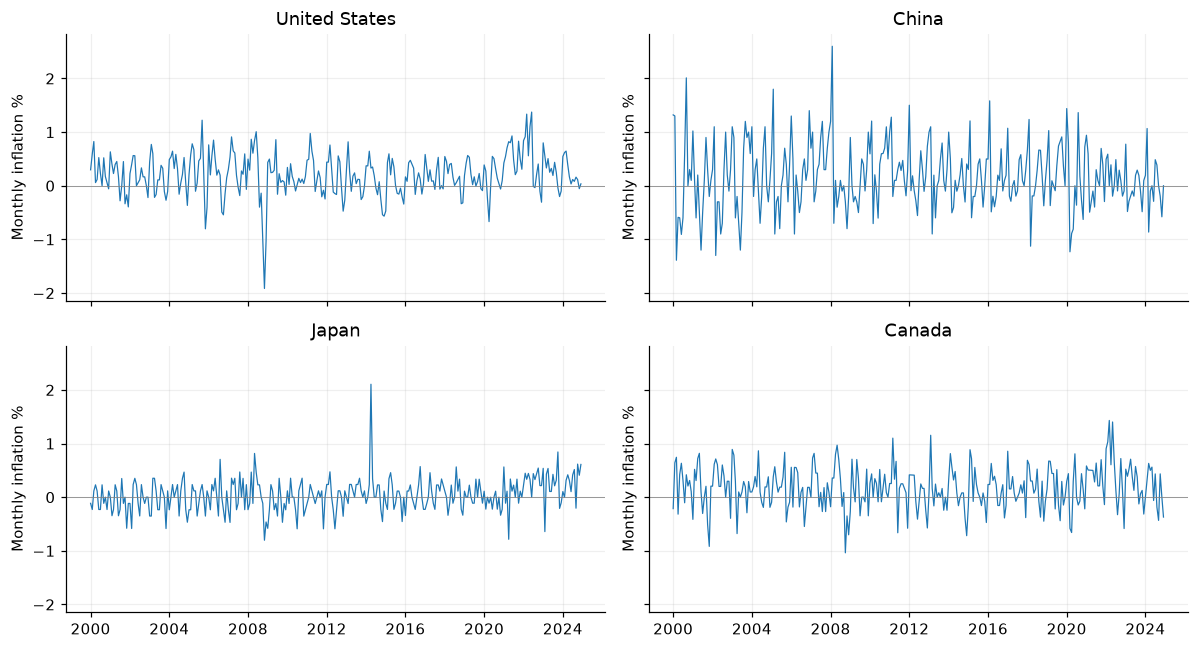

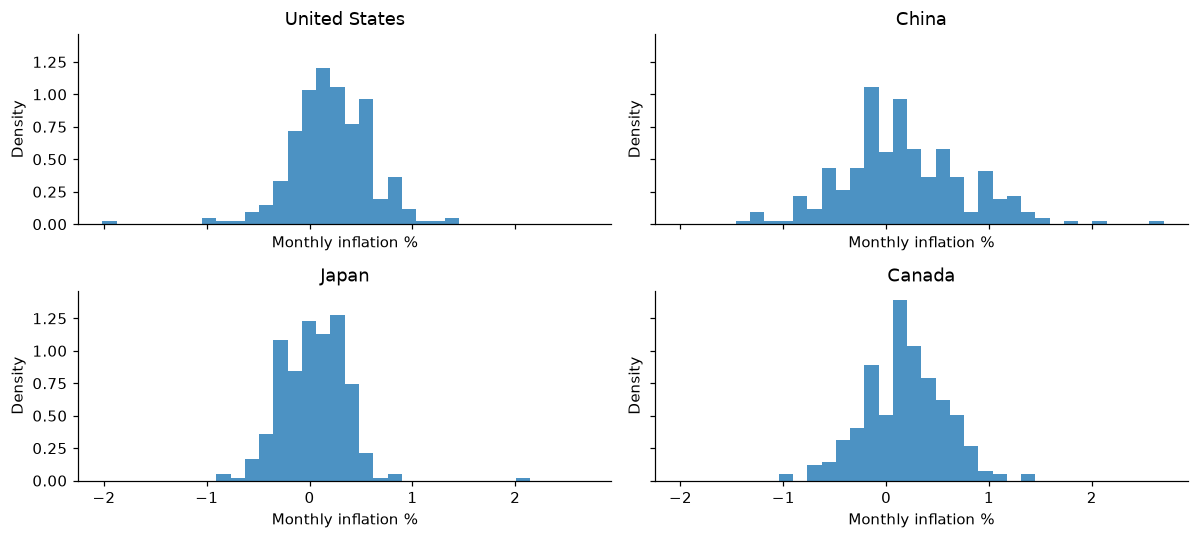

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    ax.plot(g.date,g.monthly,linewidth=.8);ax.axhline(0,color='grey',linewidth=.5)
    ax.set_title(COUNTRIES[iso]);ax.set_ylabel('Monthly inflation %');ax.grid(alpha=.2)
save_figure('inflation_histories')
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey=True)
bins = np.linspace(panel.monthly.min()-.1,panel.monthly.max()+.1,35)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    ax.hist(g.monthly,bins=bins,density=True,alpha=.8)
    ax.set_title(COUNTRIES[iso]);ax.set_xlabel('Monthly inflation %');ax.set_ylabel('Density')
save_figure('inflation_distributions')

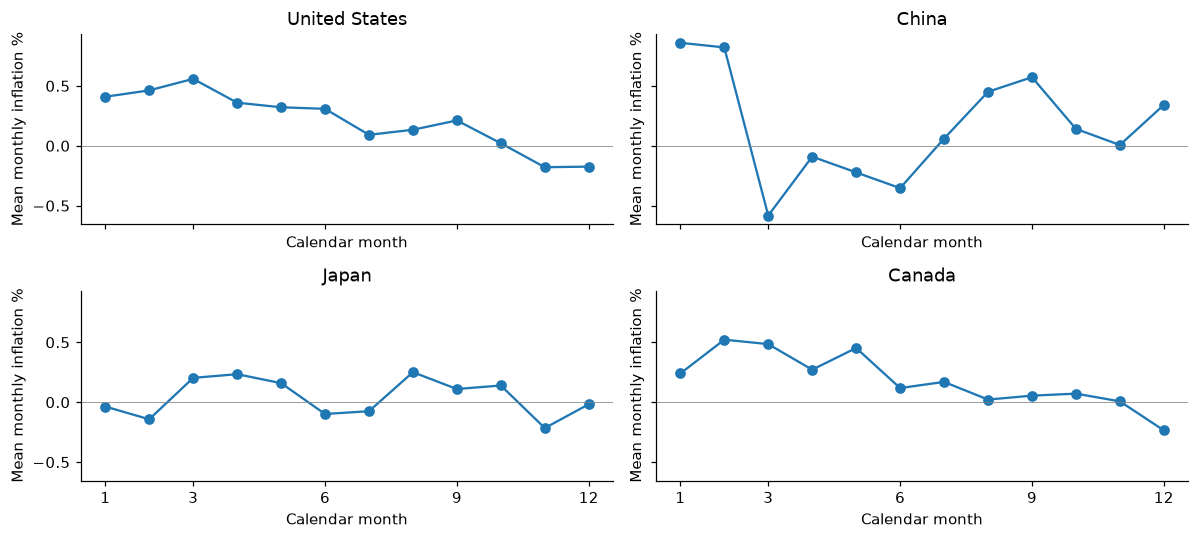

Calendar means are descriptive full-period summaries, not training-period forecast predictors.
Moving holidays and changes in seasonal patterns remain potential model failures.


In [5]:
seasonal = panel.groupby(['iso3','month']).monthly.agg(['mean','std','count']).reset_index()
seasonal.to_csv(OUT/'descriptive_month_patterns.csv',index=False)
fig, axes = plt.subplots(2,2,figsize=(11,5),sharex=True,sharey=True)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    s=seasonal[seasonal.iso3.eq(iso)]
    ax.plot(s.month,s['mean'],marker='o');ax.axhline(0,color='grey',linewidth=.5)
    ax.set_xticks([1,3,6,9,12]);ax.set_xlabel('Calendar month');ax.set_title(COUNTRIES[iso])
    ax.set_ylabel('Mean monthly inflation %')
save_figure('calendar_patterns')
print('Calendar means are descriptive full-period summaries, not training-period forecast predictors.')
print('Moving holidays and changes in seasonal patterns remain potential model failures.')

## 4. Causal model and identification assumptions
Our three-node hypothesis is $C_t\rightarrow T_t$, $C_t\rightarrow Y_{it}$ and
$T_t\rightarrow Y_{it}$. Higher global demand may raise both oil prices and domestic inflation.
Measuring the proxy before the treatment avoids treating an obvious post-treatment measurement as a
confounder, but does not make the proxy exogenous or sufficient. We do not label oil movements clean
supply shocks or interpret Bayesian computation as establishing causality.

A causal interpretation additionally needs consistency of the treatment contrast, sufficient overlap,
no remaining relevant confounding after the proposed adjustment, and an adequate temporal model.
Exchange rates, supply constraints, taxes, administered prices and policy feedback can violate that
argument. Country-specific seasonality and AR errors are statistical nuisance structure; they do not
automatically satisfy a strict three-variable causal restriction. We must justify this scope explicitly.

[Presno and Prestipino (2024)](https://www.federalreserve.gov/econres/notes/feds-notes/oil-price-shocks-and-inflation-in-a-dsge-model-of-the-global-economy-20240802.html)
motivate consumer-energy and production-cost pathways. Their structural supply-shock effect and
horizon differ from our nominal-price observational contrast, so their effect size is not copied as our prior.

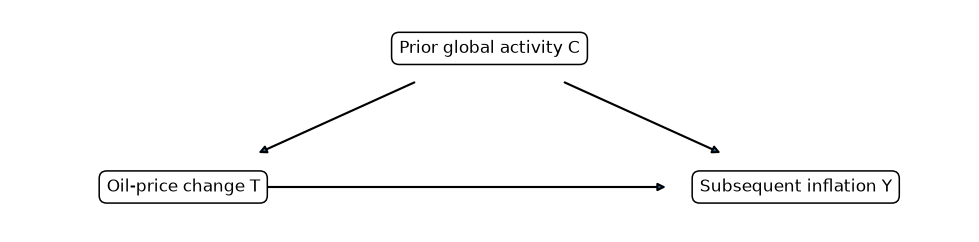

In [6]:
fig, ax = plt.subplots(figsize=(9,2.3));ax.axis('off')
positions={'C':(.5,.83),'T':(.18,.2),'Y':(.82,.2)}
for start,end in [('C','T'),('C','Y'),('T','Y')]:
    ax.annotate('',xy=positions[end],xytext=positions[start],xycoords='axes fraction',
                arrowprops={'arrowstyle':'-|>','linewidth':1.4,'shrinkA':54,
                            'shrinkB':85 if start=='T' else 54})
for key,label in [('C','Prior global activity C'),('T','Oil-price change T'),('Y','Subsequent inflation Y')]:
    ax.text(*positions[key],label,transform=ax.transAxes,ha='center',va='center',fontsize=11,
            bbox={'boxstyle':'round,pad=.45','fc':'white','ec':'black'})
save_figure('causal_dag')

## 5. Baseline model, priors and prior predictive checks
For each country, separately:
$$Y_{it}=\alpha_i+\beta_iT_t+\gamma_iC_t+s_{i,m(t)}+u_{it},\quad
u_{it}=\phi_i u_{i,t-1}+\epsilon_{it},\quad \epsilon_{it}\sim\mathcal N(0,\sigma_i^2).$$
The initial residual has $u_{i0}\sim\mathcal N(0,\sigma_i^2/(1-\phi_i^2))$ and $|\phi_i|<1$.
Eleven fixed orthonormal month contrasts represent seasonal effects summing to zero. Omitting C will
remove gamma only; seasonal structure, likelihood and prior choices remain matched.

Independent working priors are $\alpha_i,\gamma_i,\delta_{ik}\sim\mathcal N(0,0.5^2)$,
$\beta_i\sim\mathcal N(0,0.3^2)$, $\sigma_i\sim\mathrm{HalfNormal}(0.5)$,
and $\phi_i\sim\mathrm{Uniform}(-1,1)$. These are the existing baseline priors in interpretable units.
For external scale context, the [Fed's 2% long-run **PCE**, not CPI, objective](https://www.federalreserve.gov/faqs/economy_14400.htm)
corresponds to approximately 0.165% monthly growth. It motivates small monthly units, not a CPI target
or an assumed target for all four countries. Centering alpha at zero with SD 0.5 allows deflation and
substantial departures from that context. Beta's central 95% prior range is about ±0.59 percentage
points per 10-point oil movement; this is deliberately broad relative to the modest transmission in
Presno/Prestipino's different annual supply-shock setting. We do not equate their estimand to ours.
Gamma and seasonal contrast SDs of 0.5 allow large monthly deviations while shrinking unstable terms;
the half-Normal residual scale allows occasional substantial shocks. Uniform phi permits either sign
and broad persistence; prior prediction exposes the near-unit-root tail. These are weak modeling
judgments rather than parameters learned from our outcomes; their sensitivity is reported below.

The alternative fixes nu=5 before final estimation: innovations have Student-t scale sigma, with SD
sigma*sqrt(5/3). Its initial residual is independently t_5(0,sigma/sqrt(1-phi²)). This matches the AR
stationary variance but is **not** asserted to be the exact stationary t-AR marginal distribution.
Identical priors are used on scale parameters, so innovation variance priors are larger for Student-t.
We compare predictive adequacy, not an allegedly prior-free Bayes factor. Heavy tails cannot fix
omitted confounding or every remaining dependence pattern. Fixed nu also avoids tuning for oil signs.
Explicitly, the alternative has $\epsilon_{it}\sim t_5(0,\sigma_i)$ and
$\sqrt{1-\phi_i^2}\,u_{i0}\sim t_5(0,\sigma_i)$, independently of subsequent innovations.

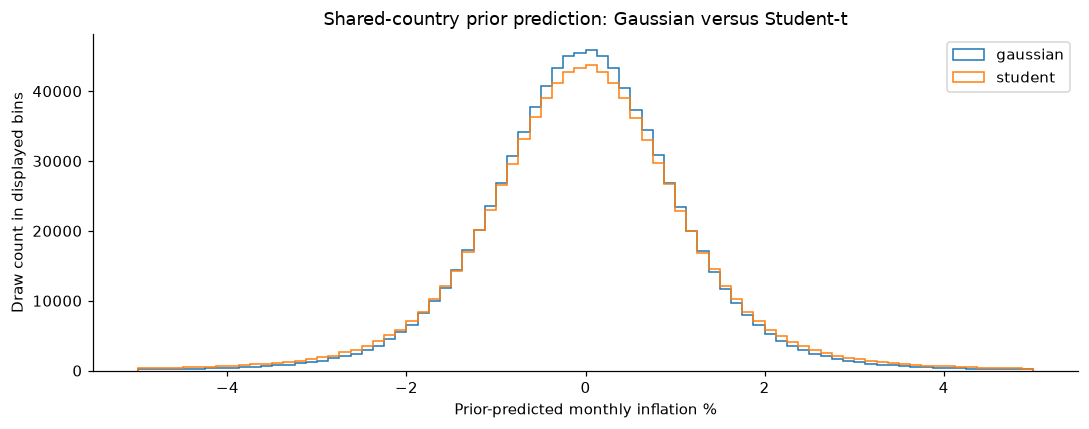

,family,lower95,median,upper95,fraction_abs_inflation_above_5
0,gaussian,-2.3433,-0.0025,2.3249,0.0064
1,student,-2.7283,-0.0018,2.6730,0.0117


Histogram display is limited to [-5,5]; the table reports tail mass, not hidden truncation.
The prior is conditional on shared predictors, before observing inflation; no country inflation is used.


In [7]:
# Shared dates, T and C imply identical prior-predictive distributions for all countries.
X,names,scales=design(groups['USA'])
for g in groups.values():
    assert np.allclose(design(g)[0],X)
count=3000
coefficients=RNG.normal(size=(count,len(names)))*scales
sigma=np.abs(RNG.normal(0,.5,count));phi=RNG.uniform(-1,1,count)
prior_rows=[]
for family in ['gaussian','student']:
    noise=(RNG.standard_t(5,size=(count,len(X))) if family=='student' else RNG.normal(size=(count,len(X))))*sigma[:,None]
    errors=np.empty_like(noise);errors[:,0]=noise[:,0]/np.sqrt(1-phi**2)
    for j in range(1,len(X)):errors[:,j]=phi*errors[:,j-1]+noise[:,j]
    predicted=coefficients@X.T+errors
    lo,mid,hi=np.quantile(predicted,[.025,.5,.975]);outside=np.mean(np.abs(predicted)>5)
    prior_rows.append({'family':family,'lower95':lo,'median':mid,'upper95':hi,'fraction_abs_inflation_above_5':outside})
    plt.hist(predicted.ravel(),bins=np.linspace(-5,5,81),histtype='step',label=family)
prior_summary=pd.DataFrame(prior_rows)
plt.title('Shared-country prior prediction: Gaussian versus Student-t')
plt.xlabel('Prior-predicted monthly inflation %');plt.ylabel('Draw count in displayed bins');plt.legend()
save_figure('prior_predictive')
prior_summary.to_csv(OUT/'prior_predictive_summary.csv',index=False)
display(prior_summary.round(4))
print('Histogram display is limited to [-5,5]; the table reports tail mass, not hidden truncation.')
print('The prior is conditional on shared predictors, before observing inflation; no country inflation is used.')

## 6. Simulation validation
We generate a separate 300-month system with C driving both T and Y, seasonal effects, and dependent
errors. True beta=.15, gamma=.25, sigma=.15 and phi=.4. Each likelihood is fitted to its corresponding
simulated data, with and without C. No synthetic row is merged with real measurements. One recovery
experiment per family tests implementation under known assumptions; it is not a repeated-coverage study.

The Student-t sampler uses a Normal/Gamma scale mixture: lambda_t~Gamma(nu/2,nu/2) in shape/rate
parameterization; whitened residuals
conditional on lambda_t are Normal(0,sigma²/lambda_t). Coefficients have exact Gaussian Gibbs updates;
log(sigma) and atanh(phi) use Metropolis updates with Jacobians. Each fit has four seeded chains,
1,500 warmup and 4,000 retained iterations per chain. Adaptation stops after warmup; there is no thinning.
Independent unit tests check the integrated mixture density and Gaussian joint AR covariance.

simulation/gaussian/adjusted=False cache sampling pass: True


simulation/gaussian/adjusted=True cache sampling pass: True


simulation/student/adjusted=False cache sampling pass: True


simulation/student/adjusted=True cache sampling pass: True


,family,adjusted,parameter,mean,lower95,upper95,truth,truth_in_95
1,gaussian,False,beta,0.1983,0.1727,0.2236,NaN,NaN
16,gaussian,True,beta,0.1502,0.1285,0.1716,0.15,True
17,gaussian,True,gamma,0.2400,0.2031,0.2772,0.25,True
32,student,False,beta,0.2021,0.1721,0.2330,NaN,NaN
47,student,True,beta,0.1456,0.1189,0.1726,0.15,True
48,student,True,gamma,0.2618,0.2170,0.3070,0.25,True


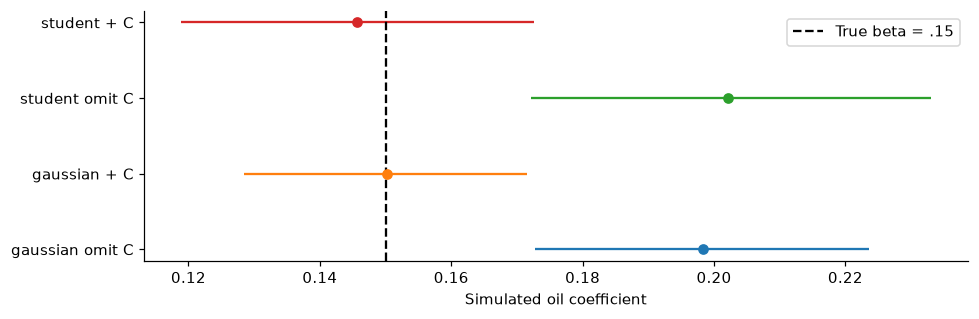

In [8]:
from analysis.robust_model import (specification, fit_cached, simulation_data,
                                   posterior_replications, one_step_forecast, point_loglik)
from analysis.model import summarize
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.special import logsumexp
import statsmodels.api as sm

simulation_tables=[];simulation_betas=[]
for fi,family in enumerate(['gaussian','student']):
    simulated,truth=simulation_data(family)
    for adjusted in [False,True]:
        fit=fit_cached(simulated,adjusted=adjusted,family=family,seed=3000+fi*100+int(adjusted),
                       label=f'simulation/{family}/adjusted={adjusted}')
        table=fit['diagnostics'].copy();table['family']=family;table['adjusted']=adjusted
        if adjusted:
            table['truth']=truth
            table['truth_in_95']=(table.truth>=table.lower95)&(table.truth<=table.upper95)
        simulation_tables.append(table)
        row=table[table.parameter.eq('beta')].iloc[0]
        simulation_betas.append({'family':family,'adjusted':adjusted,'mean':row['mean'],'lower95':row.lower95,'upper95':row.upper95,'truth':.15})
simulation=pd.concat(simulation_tables,ignore_index=True)
simulation.to_csv(OUT/'simulation_recovery.csv',index=False)
display(simulation[simulation.parameter.isin(['beta','gamma'])][['family','adjusted','parameter','mean','lower95','upper95','truth','truth_in_95']].round(4))
fig,ax=plt.subplots(figsize=(9,3))
for j,row in enumerate(simulation_betas):
    ax.errorbar(row['mean'],j,xerr=[[row['mean']-row['lower95']],[row['upper95']-row['mean']]],fmt='o')
ax.axvline(.15,color='black',linestyle='--',label='True beta = .15')
ax.set_yticks(range(4),[r['family']+(' + C' if r['adjusted'] else ' omit C') for r in simulation_betas])
ax.set_xlabel('Simulated oil coefficient');ax.legend();save_figure('simulation_recovery')
assert simulation.sampling_pass.all(), 'Inspect synthetic-chain diagnostics before continuing'

## 7. Real-data estimation and sampling checks
Both families are fitted separately in every country, retaining or omitting only C. All full-data
coefficients and priors share the stated units. Reproducible fits are cached locally using model-source,
data, prior and sampler hashes; cache hits are recorded rather than presented as new sampling runs.
Rank-normalized R-hat <1.01 and bulk/tail ESS >400 are required for every parameter before interpretation.
Conditional oil intervals are not formal tests of country differences, and model failures remain relevant.

full/USA/gaussian/adjusted=False cache sampling pass: True


full/USA/gaussian/adjusted=True cache sampling pass: True


full/USA/student/adjusted=False cache sampling pass: True


full/USA/student/adjusted=True cache sampling pass: True


full/CHN/gaussian/adjusted=False cache sampling pass: True


full/CHN/gaussian/adjusted=True cache sampling pass: True


... (10 outputs left out)

full/CAN/student/adjusted=True cache sampling pass: True


,iso3,family,adjusted,beta,lower95,upper95,P_beta_positive
0,USA,gaussian,False,0.0943,0.0588,0.1312,1.0000
1,USA,gaussian,True,0.0954,0.0598,0.1313,1.0000
2,USA,student,False,0.0873,0.0548,0.1241,1.0000
3,USA,student,True,0.0910,0.0584,0.1267,1.0000
4,CHN,gaussian,False,0.0871,0.0386,0.1359,0.9996
5,CHN,gaussian,True,0.0836,0.0350,0.1316,0.9998
6,CHN,student,False,0.0931,0.0481,0.1384,1.0000
7,CHN,student,True,0.0916,0.0464,0.1363,1.0000
8,JPN,gaussian,False,0.0352,0.0047,0.0663,0.9882
9,JPN,gaussian,True,0.0349,0.0039,0.0662,0.9867


max_Rhat  min_bulk_ESS  min_tail_ESS
iso3 family   adjusted                                      
CAN  gaussian False          1.0       2796.47       3449.08
              True           1.0       2882.89       3472.18
     student  False          1.0       2162.81       2955.36
              True           1.0       2042.92       2702.02
CHN  gaussian False          1.0       3330.67       3720.84
              True           1.0       3326.58       3689.51
     student  False          1.0       1981.56       2771.69
              True           1.0       1743.08       2620.52
JPN  gaussian False          1.0       3378.14       3936.26
              True           1.0       3213.33       3652.67
     student  False          1.0       2086.85       2950.34
              True           1.0       2212.38       2752.32
USA  gaussian False          1.0       2426.62       3068.37
              True           1.0       2114.84       3178.68
     student  False          1.0       1509.19       2653.94
              True           1.0       1566.57       2400.28

P_beta_positive is a finite-draw fraction; a displayed 1.0 is not logical certainty or a causal probability.


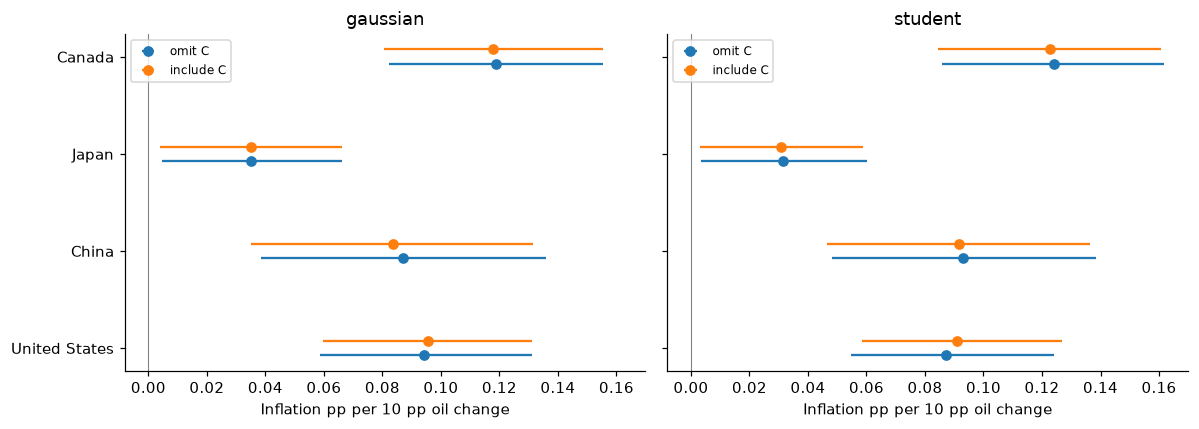

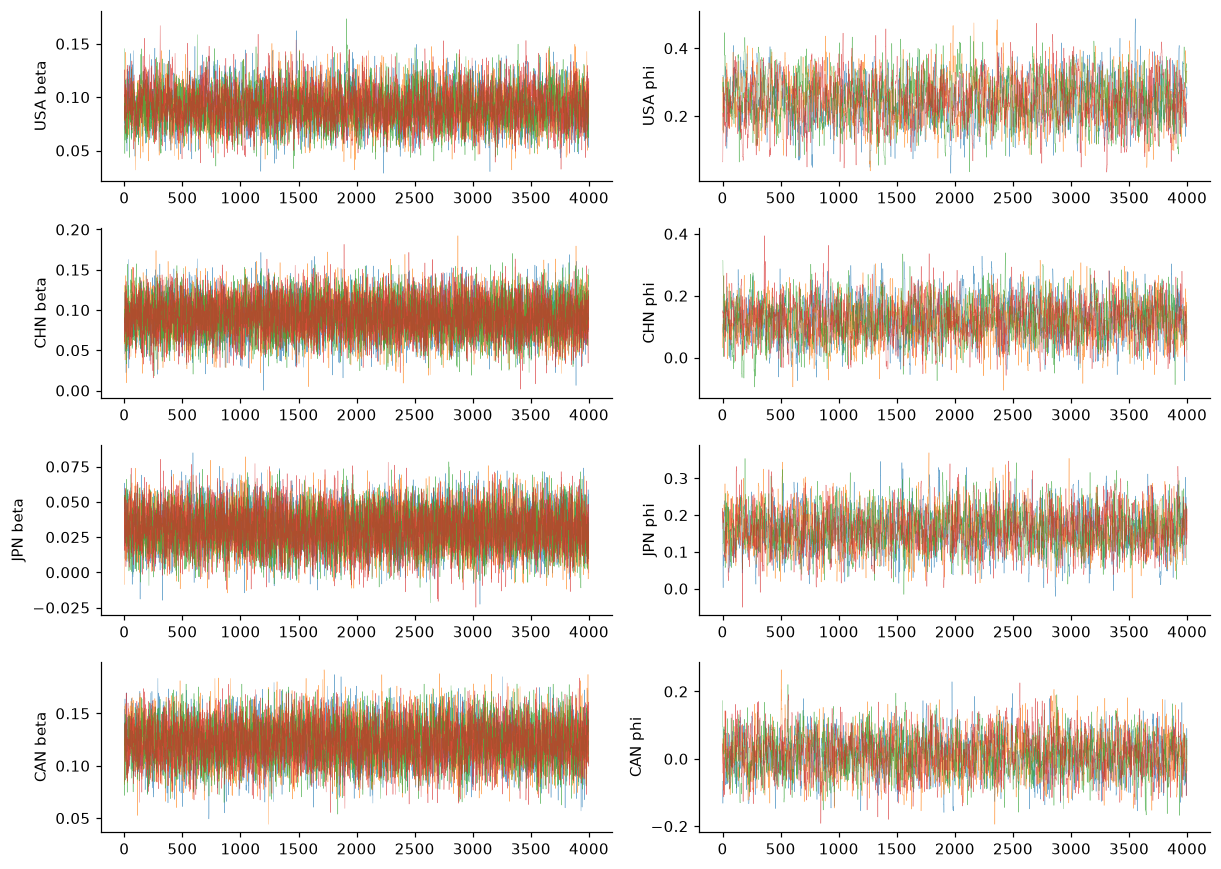

In [9]:
fits={};diagnostic_tables=[];coefficient_rows=[];fit_records=[]
for ci,(iso,g) in enumerate(groups.items()):
    fits[iso]={}
    for fi,family in enumerate(['gaussian','student']):
        for adjusted in [False,True]:
            fit=fit_cached(g,adjusted=adjusted,family=family,seed=10000+ci*1000+fi*100+int(adjusted),
                           label=f'full/{iso}/{family}/adjusted={adjusted}')
            fits[iso][(family,adjusted)]=fit
            table=fit['diagnostics'].copy();table['iso3']=iso;table['family']=family;table['adjusted']=adjusted
            diagnostic_tables.append(table)
            row=table[table.parameter.eq('beta')].iloc[0]
            coefficient_rows.append({'iso3':iso,'family':family,'adjusted':adjusted,'beta':row['mean'],
                                     'lower95':row.lower95,'upper95':row.upper95,'P_beta_positive':np.mean(fit['chains'][:,:,1]>0)})
            fit_records.append({'iso3':iso,'family':family,'adjusted':adjusted,'cache_key':fit['key'],'cache_hit':fit['cache_hit']})
diagnostics=pd.concat(diagnostic_tables,ignore_index=True);estimates=pd.DataFrame(coefficient_rows)
diagnostics.to_csv(OUT/'posterior_diagnostics.csv',index=False);estimates.to_csv(OUT/'country_estimates.csv',index=False)
pd.DataFrame(fit_records).to_csv(OUT/'fit_provenance.csv',index=False)
sampling=diagnostics.groupby(['iso3','family','adjusted']).agg(max_Rhat=('r_hat','max'),min_bulk_ESS=('ess_bulk','min'),min_tail_ESS=('ess_tail','min'))
display(estimates.round(4));display(sampling.round(2))
print('P_beta_positive is a finite-draw fraction; a displayed 1.0 is not logical certainty or a causal probability.')
assert diagnostics.sampling_pass.all(), 'Inspect failed real-data sampling diagnostics'
fig,axes=plt.subplots(1,2,figsize=(11,4),sharex=True,sharey=True)
for ax,family in zip(axes,['gaussian','student']):
    for j,adjusted in enumerate([False,True]):
        q=estimates[(estimates.family==family)&(estimates.adjusted==adjusted)].set_index('iso3').loc[list(COUNTRIES)]
        ax.errorbar(q.beta,np.arange(4)+(j-.5)*.15,xerr=[q.beta-q.lower95,q.upper95-q.beta],fmt='o',label='include C' if adjusted else 'omit C')
    ax.axvline(0,color='grey',linewidth=.7);ax.set_title(family);ax.set_xlabel('Inflation pp per 10 pp oil change');ax.legend(loc='upper left',fontsize=8)
axes[0].set_yticks(range(4),list(COUNTRIES.values()));save_figure('country_coefficients')
fig,axes=plt.subplots(4,2,figsize=(11,8))
for i,(iso,g) in enumerate(groups.items()):
    a=fits[iso][('student',True)]['chains']
    for chain in range(4):
        axes[i,0].plot(a[chain,:,1],linewidth=.3,alpha=.65)
        axes[i,1].plot(a[chain,:,-1],linewidth=.3,alpha=.65)
    axes[i,0].set_ylabel(iso+' beta');axes[i,1].set_ylabel(iso+' phi')
save_figure('student_traces')

## 8. Model evaluation and sensitivity
Posterior replications include regression-mean uncertainty, parameter uncertainty and new dependent
residuals. Student-t comparisons use the stated initial distribution. We check extrema, variance and
persistence, plus plug-in innovation dependence at 6/12 lags. These approximate diagnostics are not a
guarantee of an adequate time-series likelihood. Full-sample seasonal plots are not forecast inputs.

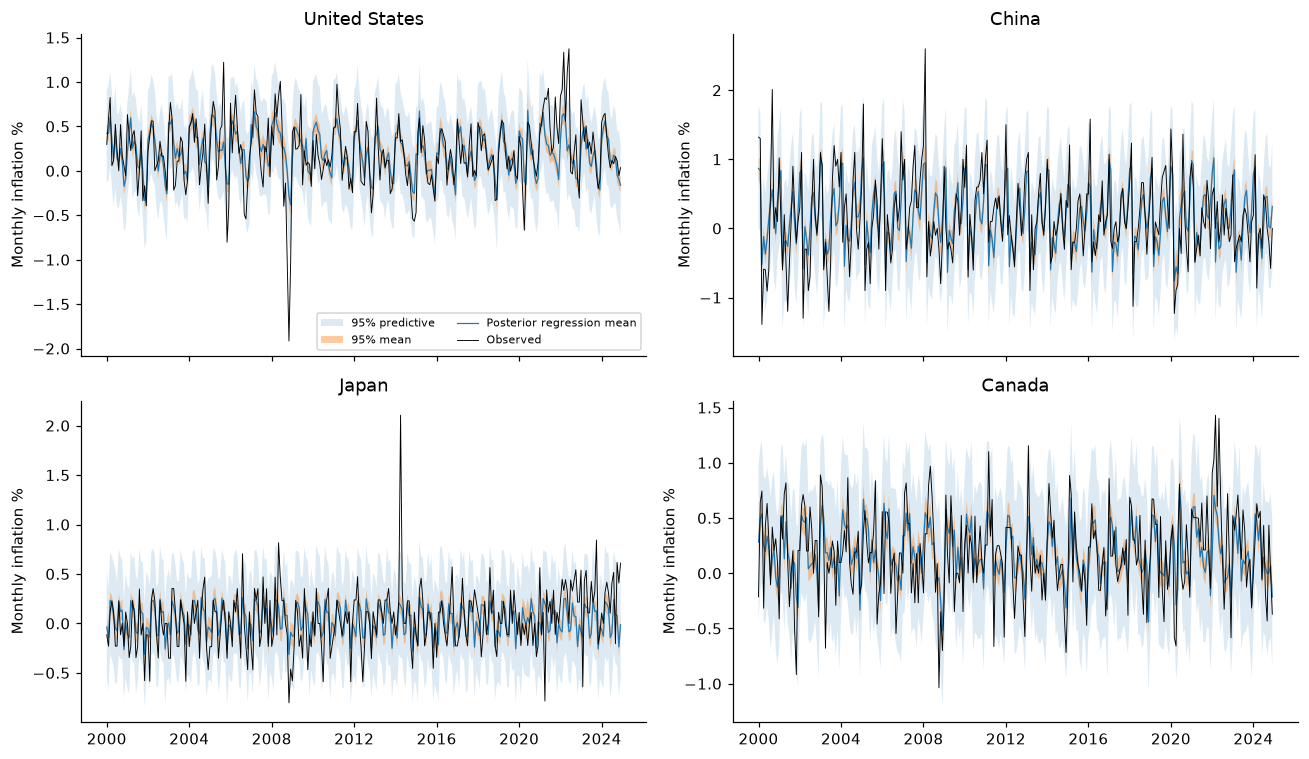

,iso3,family,statistic,observed,rep_lower95,rep_upper95,P_rep_ge_observed,outside_rep_95
0,USA,gaussian,minimum,-1.9153,-1.1740,-0.6185,1.0000,True
1,USA,gaussian,maximum,1.3736,1.0148,1.5521,0.1633,False
4,USA,student,minimum,-1.9153,-1.9475,-0.5928,0.9740,False
5,USA,student,maximum,1.3736,0.9908,2.2776,0.4247,False
8,CHN,gaussian,minimum,-1.3889,-1.9418,-1.1298,0.3507,False
9,CHN,gaussian,maximum,2.6000,1.4700,2.2852,0.0020,True
12,CHN,student,minimum,-1.3889,-3.2905,-1.2006,0.1387,False
13,CHN,student,maximum,2.6000,1.5349,3.7051,0.1720,False
16,JPN,gaussian,minimum,-0.8028,-1.1494,-0.6457,0.3840,False
17,JPN,gaussian,maximum,2.1053,0.7287,1.1819,0.0000,True


,lag,lb_stat,lb_pvalue,iso3,family
1,12,20.8129,0.0532,USA,gaussian
3,12,23.2652,0.0256,USA,student
5,12,24.6330,0.0167,CHN,gaussian
7,12,25.1731,0.0140,CHN,student
9,12,27.2799,0.0070,JPN,gaussian
11,12,30.0747,0.0027,JPN,student
13,12,16.5721,0.1664,CAN,gaussian
15,12,16.6058,0.1650,CAN,student


**Shared-shock check:** residual innovation correlations below reinforce why separate country fits do not form an independent pooled sample.

,USA,CHN,JPN,CAN
USA,1.000,0.132,0.172,0.61
CHN,0.132,1.000,0.052,0.09
JPN,0.172,0.052,1.000,0.15
CAN,0.610,0.090,0.150,1.00


In [10]:
pp_rows=[];lb_rows=[];innovations={};fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ci,(ax,(iso,g)) in enumerate(zip(axes.flat,groups.items())):
    for fi,family in enumerate(['gaussian','student']):
        fit=fits[iso][(family,True)];mu,rep=posterior_replications(fit,seed=800+ci*10+fi,count=1500)
        mean=fit['chains'].mean(axis=(0,1));res=g.monthly.to_numpy()-fit['X']@mean[:-2]
        innov=res[1:]-mean[-1]*res[:-1]
        lb=acorr_ljungbox(innov,lags=[6,12],return_df=True).rename_axis('lag').reset_index()
        lb['iso3']=iso;lb['family']=family;lb_rows.append(lb)
        for name,fun in [('minimum',np.min),('maximum',np.max),('sd',np.std),('lag1',lambda x:pd.Series(x).autocorr())]:
            values=np.array([fun(v) for v in rep]);obs=fun(g.monthly.to_numpy());lo,hi=np.quantile(values,[.025,.975])
            pp_rows.append({'iso3':iso,'family':family,'statistic':name,'observed':obs,'rep_lower95':lo,'rep_upper95':hi,
                            'P_rep_ge_observed':np.mean(values>=obs),'outside_rep_95':bool(obs<lo or obs>hi)})
        if family=='student':
            innovations[iso]=innov
            ax.fill_between(g.date,*np.quantile(rep,[.025,.975],axis=0),alpha=.15,label='95% predictive')
            ax.fill_between(g.date,*np.quantile(mu,[.025,.975],axis=0),alpha=.4,label='95% mean')
            ax.plot(g.date,mu.mean(axis=0),linewidth=.8,label='Posterior regression mean')
            ax.plot(g.date,g.monthly,color='black',linewidth=.6,label='Observed');ax.set_title(COUNTRIES[iso])
            ax.set_ylabel('Monthly inflation %')
axes[0,0].legend(fontsize=7,ncol=2);save_figure('student_posterior_predictive')
predictive=pd.DataFrame(pp_rows);lb=pd.concat(lb_rows,ignore_index=True)
predictive.to_csv(OUT/'predictive_checks.csv',index=False);lb.to_csv(OUT/'innovation_checks.csv',index=False)
display(predictive[predictive.statistic.isin(['minimum','maximum'])].round(4))
display(lb[lb.lag.eq(12)].round(4))
innovation_correlation=pd.DataFrame(innovations).corr()
innovation_correlation.to_csv(OUT/'cross_country_innovation_correlation.csv')
display(Markdown('**Shared-shock check:** residual innovation correlations below reinforce why separate country fits do not form an independent pooled sample.'))
display(innovation_correlation.round(3))

In [11]:
prior_rows=[];sensitivity=[]
for iso,g in groups.items():
    fit=fits[iso][('student',True)];flat=fit['chains'].reshape(-1,len(fit['names'])+2)
    for label,logweight in [('beta SD .15',-.5*(flat[:,1]/.15)**2+.5*(flat[:,1]/.3)**2),
                            ('beta SD .60',-.5*(flat[:,1]/.6)**2+.5*(flat[:,1]/.3)**2),
                            ('phi transformed Beta(2,2)',np.log1p(-flat[:,-1]**2))]:
        w=np.exp(logweight-logweight.max());w/=w.sum();order=np.argsort(flat[:,1])
        lo,hi=np.interp([.025,.975],np.cumsum(w[order]),flat[order,1])
        prior_rows.append({'iso3':iso,'alternative_prior':label,'beta':w@flat[:,1],'lower95':lo,'upper95':hi,
                           'weight_ESS':1/(w@w)})
    for label,h in [('2000-2019',g[g.date<'2020-01-01']),('2020-2024',g[g.date>='2020-01-01']),
                    ('exclude 2020-2022',g[~g.date.dt.year.between(2020,2022)]),('exclude |oil change| >30%',g[g['T'].abs()<=3])]:
        r=sm.OLS(h.monthly,specification(h)[0]).fit(cov_type='HAC',cov_kwds={'maxlags':12});ci=np.asarray(r.conf_int())[1]
        sensitivity.append({'iso3':iso,'sample':label,'n':len(h),'beta_OLS':np.asarray(r.params)[1],'HAC_lower':ci[0],'HAC_upper':ci[1]})
priors=pd.DataFrame(prior_rows);robustness=pd.DataFrame(sensitivity)
priors.to_csv(OUT/'prior_sensitivity.csv',index=False);robustness.to_csv(OUT/'subperiod_sensitivity.csv',index=False)
display(priors.round(4));display(robustness.round(4))
display(Markdown('Prior reweighting ESS assesses weight concentration, not replacement-chain mixing. HAC OLS checks use a different estimator and are exploratory; removing calendar segments also complicates lag-based inference. Fixed nu=5 remains an untested shape assumption beyond the Gaussian comparison.'))

,iso3,alternative_prior,beta,lower95,upper95,weight_ESS
0,USA,beta SD .15,0.0901,0.0576,0.1254,15954.6659
1,USA,beta SD .60,0.0913,0.0586,0.1271,15997.0086
2,USA,"phi transformed Beta(2,2)",0.0913,0.0588,0.1271,15980.3403
3,CHN,beta SD .15,0.0900,0.0451,0.1345,15923.5405
4,CHN,beta SD .60,0.0920,0.0467,0.1368,15994.8827
5,CHN,"phi transformed Beta(2,2)",0.0916,0.0464,0.1364,15995.6908
6,JPN,beta SD .15,0.0307,0.0028,0.0586,15996.2199
7,JPN,beta SD .60,0.0310,0.0030,0.0590,15999.7580
8,JPN,"phi transformed Beta(2,2)",0.0310,0.0030,0.0590,15994.5175
9,CAN,beta SD .15,0.1213,0.0830,0.1590,15903.0031


,iso3,sample,n,beta_OLS,HAC_lower,HAC_upper
0,USA,2000-2019,240,0.1784,0.1094,0.2475
1,USA,2020-2024,60,0.0984,0.0713,0.1255
2,USA,exclude 2020-2022,264,0.1689,0.0990,0.2387
3,USA,exclude |oil change| >30%,296,0.1656,0.0993,0.2319
4,CHN,2000-2019,240,0.0822,0.0244,0.1400
5,CHN,2020-2024,60,0.1104,0.0638,0.1570
6,CHN,exclude 2020-2022,264,0.0770,0.0202,0.1338
7,CHN,exclude |oil change| >30%,296,0.0977,0.0467,0.1487
8,JPN,2000-2019,240,0.0488,0.0009,0.0967
9,JPN,2020-2024,60,0.0042,-0.0300,0.0385


Prior reweighting ESS assesses weight concentration, not replacement-chain mixing. HAC OLS checks use a different estimator and are exploratory; removing calendar segments also complicates lag-based inference. Fixed nu=5 remains an untested shape assumption beyond the Gaussian comparison.

### Retrospective prediction and matched no-oil comparison
Train on 2000–2019 only, then predict each month of 2020–2024 using observed previous residuals.
Student-t models with/without oil have the same C, month structure, priors on retained parameters and
likelihood. Gaussian oil forecasts and simple benchmarks provide context. Fixed coefficients and
training-only seasonal estimates prevent test-outcome refitting. Revised source data and publication
assumptions still prevent a real-time forecast claim. The test period informed earlier exploratory work.

training/USA/gaussian/oil=True cache sampling pass: True


training/USA/student/oil=True cache sampling pass: True


training/USA/student/oil=False cache sampling pass: True


training/CHN/gaussian/oil=True cache sampling pass: True


training/CHN/student/oil=True cache sampling pass: True


training/CHN/student/oil=False cache sampling pass: True


... (3 outputs left out)

training/CAN/gaussian/oil=True cache sampling pass: True


training/CAN/student/oil=True

 cache sampling pass: True


training/CAN/student/oil=False cache sampling pass: True


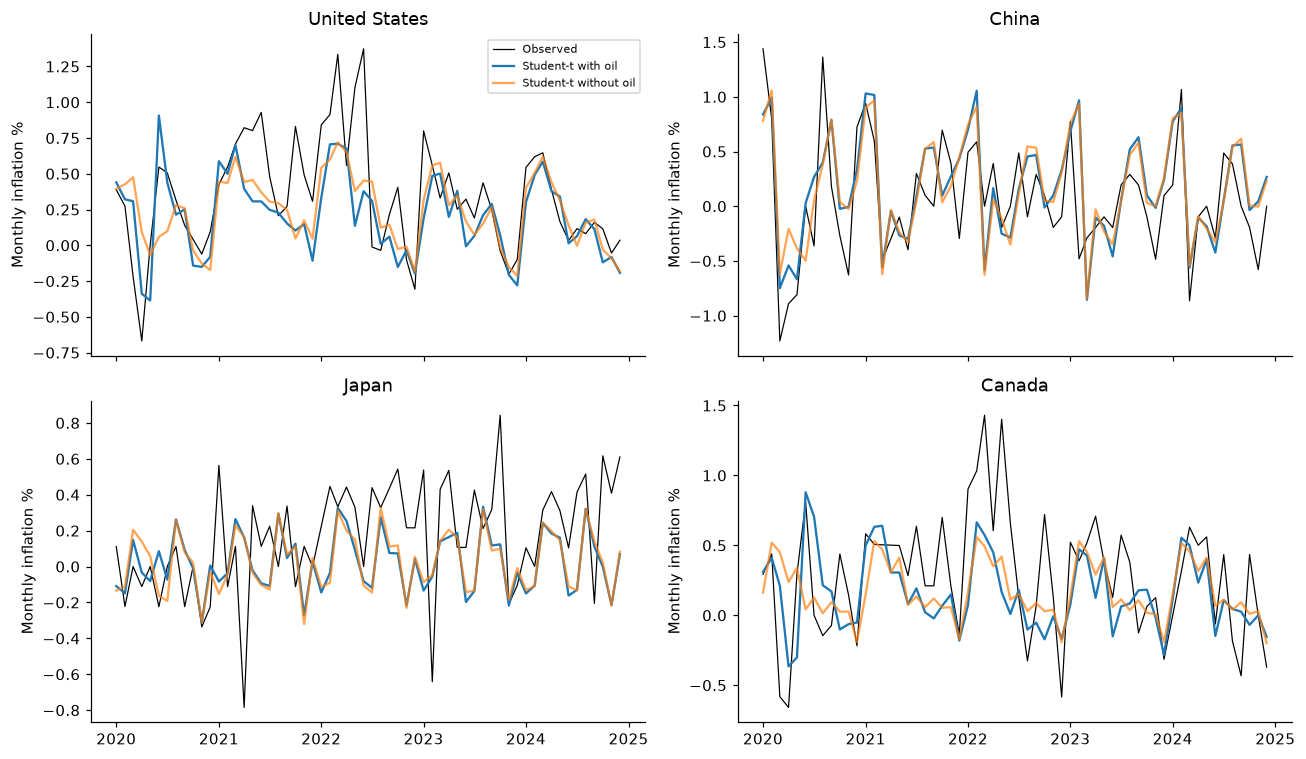

,iso3,model,test_n,MAE,RMSE,coverage95,mean_log_predictive_density
0,USA,gaussian + oil,60,0.2459,0.3363,0.8667,-0.3920
1,USA,student + oil,60,0.2394,0.3308,0.8333,-0.3168
2,USA,student no oil,60,0.2268,0.3175,0.8833,-0.2491
3,USA,last month,60,0.2749,0.3765,NaN,NaN
4,USA,training month mean,60,0.2765,0.3883,NaN,NaN
5,USA,training mean,60,0.3236,0.4231,NaN,NaN
6,USA,same month last year,60,0.3604,0.4812,NaN,NaN
7,CHN,gaussian + oil,60,0.3406,0.4213,0.9667,-0.5566
8,CHN,student + oil,60,0.3406,0.4247,0.9667,-0.5686
9,CHN,student no oil,60,0.3647,0.4461,0.9667,-0.6347


,iso3,RMSE_with_oil,RMSE_without_oil,RMSE_reduction_percent,log_score_gain
0,USA,0.331,0.318,-4.168,-0.068
1,CHN,0.425,0.446,4.789,0.066
2,JPN,0.352,0.353,0.247,-0.004
3,CAN,0.398,0.389,-2.529,-0.064


In [12]:
forecast_rows=[];forecast_detail=[];training_tables=[];oil_rows=[];fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ci,(ax,(iso,g)) in enumerate(zip(axes.flat,groups.items())):
    train=g[g.date<'2020-01-01'];test=g[g.date>='2020-01-01'];forecasts={}
    for fi,family in enumerate(['gaussian','student']):
        for oil in ([True] if family=='gaussian' else [True,False]):
            fit=fit_cached(train,family=family,oil=oil,seed=20000+ci*1000+fi*100+int(oil),
                           label=f'training/{iso}/{family}/oil={oil}')
            table=fit['diagnostics'].copy();table['iso3']=iso;table['family']=family;table['oil']=oil;training_tables.append(table)
            result=one_step_forecast(fit,g,seed=400+ci*10+fi+int(oil))
            label=family+(' + oil' if oil else ' no oil');forecasts[label]=result
            forecast_rows.append({'iso3':iso,'model':label,'test_n':60,**{k:result[k] for k in ['MAE','RMSE','coverage95','mean_log_predictive_density']}})
            for j,date in enumerate(test.date):
                forecast_detail.append({'iso3':iso,'model':label,'date':date,'actual':test.monthly.iloc[j],
                                        'prediction':result['prediction'][j],'lower95':result['lower95'][j],'upper95':result['upper95'][j]})
    for label,pred in [('last month',test.last_monthly.to_numpy()),('training month mean',test.month.map(train.groupby('month').monthly.mean()).to_numpy()),
                       ('training mean',np.repeat(train.monthly.mean(),60)),('same month last year',test.last_year_same_month.to_numpy())]:
        error=test.monthly.to_numpy()-pred
        forecast_rows.append({'iso3':iso,'model':label,'test_n':60,'MAE':np.abs(error).mean(),'RMSE':np.sqrt(np.mean(error**2))})
    full,nooil=forecasts['student + oil'],forecasts['student no oil']
    oil_rows.append({'iso3':iso,'RMSE_with_oil':full['RMSE'],'RMSE_without_oil':nooil['RMSE'],
                     'RMSE_reduction_percent':100*(nooil['RMSE']-full['RMSE'])/nooil['RMSE'],
                     'log_score_gain':full['mean_log_predictive_density']-nooil['mean_log_predictive_density']})
    ax.plot(test.date,test.monthly,color='black',linewidth=.8,label='Observed')
    ax.plot(test.date,full['prediction'],label='Student-t with oil')
    ax.plot(test.date,nooil['prediction'],label='Student-t without oil',alpha=.7);ax.set_title(COUNTRIES[iso]);ax.set_ylabel('Monthly inflation %')
axes[0,0].legend(fontsize=7);save_figure('holdout_predictions')
forecasts=pd.DataFrame(forecast_rows);oil_comparison=pd.DataFrame(oil_rows);training=pd.concat(training_tables,ignore_index=True)
forecasts.to_csv(OUT/'forecast_metrics.csv',index=False);oil_comparison.to_csv(OUT/'oil_forecast_comparison.csv',index=False)
pd.DataFrame(forecast_detail).to_csv(OUT/'forecast_predictions.csv',index=False);training.to_csv(OUT/'training_diagnostics.csv',index=False)
display(forecasts.round(4));display(oil_comparison.round(3))
assert training.sampling_pass.all(), 'Inspect training-model sampling diagnostics'

## 9. Findings, interpretation and limitations
The following summary is generated from the completed fits, not from anticipated coefficient signs.
The adjusted/unadjusted difference in real data is not itself a measurement of causal bias removal.
Single-country intervals do not account for shared omitted causes and do not establish country rankings.

In [13]:
lines=['# Completed four-country computational analysis','',
       'All source hashes and 1,200 country-month rows verified. All simulation, full-data and training sampling checks passed.','',
       '## Oil–inflation associations (Student-t, demand-adjusted)','']
for iso,name in COUNTRIES.items():
    a=estimates[(estimates.iso3==iso)&(estimates.family=='student')&estimates.adjusted].iloc[0]
    b=estimates[(estimates.iso3==iso)&(estimates.family=='student')&~estimates.adjusted].iloc[0]
    lines.append(f'- **{name}:** beta {a.beta:.4f}, 95% credible interval [{a.lower95:.4f}, {a.upper95:.4f}]; omitting demand gives {b.beta:.4f}.')
lines+=['','Units are monthly inflation percentage points per 10-percentage-point higher monthly oil change. These are model-conditional associations.','',
        '## Predictive checks and residual dependence','']
for iso,name in COUNTRIES.items():
    p12=lb[(lb.iso3==iso)&(lb.family=='student')&(lb.lag==12)].lb_pvalue.iloc[0]
    misses=predictive[(predictive.iso3==iso)&(predictive.family=='student')&predictive.outside_rep_95]
    stats=', '.join(misses.statistic) or 'none among the four checked summaries'
    lines.append(f'- **{name}:** Student-t 12-lag innovation p={p12:.4f}; predictive-summary misses: {stats}.')
lines+=['','## Does oil improve the matched retrospective forecast?','']
for _,r in oil_comparison.iterrows():
    direction='reduces' if r.RMSE_reduction_percent>0 else 'increases'
    lines.append(f'- **{COUNTRIES[r.iso3]}:** adding oil {direction} RMSE by {abs(r.RMSE_reduction_percent):.2f}% ({r.RMSE_without_oil:.4f} without oil versus {r.RMSE_with_oil:.4f} with oil); mean log-score gain {r.log_score_gain:.4f}.')
lines+=['','## Conclusions and future work','',
        'Oil coefficients, confounder adjustment and forecast gains answer different questions. The simulation shows what omitted-confounder bias can look like under a known DAG; real-data adjustment cannot certify that IGREA blocks every relevant path. Heavy-tailed innovations may improve extremes while leaving serial or calendar dependence. We report both families rather than selecting by significance.',
        '', 'Interpretation depends on consistency, overlap, adequate temporal structure and sufficient confounding control. Global-demand measurement error, exchange rates, subsidies, taxes, moving holidays and shared shocks remain limitations. Student-t nu=5 and the variance-matched initial distribution are additional assumptions; sigma is a scale, not the Student-t innovation SD. Prior reweighting and HAC checks do not cover every form of model uncertainty.',
        '', 'Future work should examine moving holidays and regime changes, alternative tail/dependence assumptions, local-currency oil exposure and better-identified supply shocks. Interest rates and pooled country-effect comparisons require a separate expanded design. No causal ranking across countries or real-time forecast claim follows from this analysis.']
report='\n'.join(lines)+'\n'
(OUT/'FINDINGS.md').write_text(report,encoding='utf-8')
display(Markdown(report))
print('Computational sections complete. Submission PDF pagination and the group screencast remain separate deliverables.')

# Completed four-country computational analysis

All source hashes and 1,200 country-month rows verified. All simulation, full-data and training sampling checks passed.

## Oil–inflation associations (Student-t, demand-adjusted)

- **United States:** beta 0.0910, 95% credible interval [0.0584, 0.1267]; omitting demand gives 0.0873.
- **China:** beta 0.0916, 95% credible interval [0.0464, 0.1363]; omitting demand gives 0.0931.
- **Japan:** beta 0.0309, 95% credible interval [0.0030, 0.0590]; omitting demand gives 0.0315.
- **Canada:** beta 0.1228, 95% credible interval [0.0844, 0.1608]; omitting demand gives 0.1243.

Units are monthly inflation percentage points per 10-percentage-point higher monthly oil change. These are model-conditional associations.

## Predictive checks and residual dependence

- **United States:** Student-t 12-lag innovation p=0.0256; predictive-summary misses: lag1.
- **China:** Student-t 12-lag innovation p=0.0140; predictive-summary misses: none among the four checked summaries.
- **Japan:** Student-t 12-lag innovation p=0.0027; predictive-summary misses: maximum.
- **Canada:** Student-t 12-lag innovation p=0.1650; predictive-summary misses: none among the four checked summaries.

## Does oil improve the matched retrospective forecast?

- **United States:** adding oil increases RMSE by 4.17% (0.3175 without oil versus 0.3308 with oil); mean log-score gain -0.0677.
- **China:** adding oil reduces RMSE by 4.79% (0.4461 without oil versus 0.4247 with oil); mean log-score gain 0.0662.
- **Japan:** adding oil reduces RMSE by 0.25% (0.3533 without oil versus 0.3524 with oil); mean log-score gain -0.0044.
- **Canada:** adding oil increases RMSE by 2.53% (0.3886 without oil versus 0.3984 with oil); mean log-score gain -0.0636.

## Conclusions and future work

Oil coefficients, confounder adjustment and forecast gains answer different questions. The simulation shows what omitted-confounder bias can look like under a known DAG; real-data adjustment cannot certify that IGREA blocks every relevant path. Heavy-tailed innovations may improve extremes while leaving serial or calendar dependence. We report both families rather than selecting by significance.

Interpretation depends on consistency, overlap, adequate temporal structure and sufficient confounding control. Global-demand measurement error, exchange rates, subsidies, taxes, moving holidays and shared shocks remain limitations. Student-t nu=5 and the variance-matched initial distribution are additional assumptions; sigma is a scale, not the Student-t innovation SD. Prior reweighting and HAC checks do not cover every form of model uncertainty.

Future work should examine moving holidays and regime changes, alternative tail/dependence assumptions, local-currency oil exposure and better-identified supply shocks. Interest rates and pooled country-effect comparisons require a separate expanded design. No causal ranking across countries or real-time forecast claim follows from this analysis.


Computational sections complete. Submission PDF pagination and the group screencast remain separate deliverables.


## Appendix. Computational implementation

The following source is included for code-inclusive exports and review. It is imported by the executed analysis above; these listings do not refit models.

### analysis/data.py

```python
"""Verified raw-snapshot preparation shared by the final report notebook."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
COUNTRIES = {'USA': 'United States', 'CHN': 'China', 'JPN': 'Japan', 'CAN': 'Canada'}
FLOWS = {
    'USA': 'DSD_PRICES@DF_PRICES_ALL',
    'CHN': 'DSD_PRICES@DF_PRICES_ALL',
    'JPN': 'DSD_PRICES_COICOP2018@DF_PRICES_C2018_ALL',
    'CAN': 'DSD_PRICES_COICOP2018@DF_PRICES_C2018_ALL',
}

def prepare_panel(root=ROOT):
    """Return a complete four-country panel and source verification table.

    Reference-month dates are calendar-aligned before any lag is constructed.
    Original snapshots are never revised, interpolated or silently downloaded.
    """
    root = Path(root)
    frames, audit = [], []
    for manifest_name in ['manifest.json', 'country_manifest.json']:
        manifest = json.loads((root/'data/raw'/manifest_name).read_text(encoding='utf-8'))
        for item in manifest:
            path = root/'data/raw'/item['file']
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            if digest != item['sha256']:
                raise ValueError(f"Source checksum mismatch: {item['file']}")
            audit.append({'file': item['file'], 'verified': True,
                          'recorded_retrieval_utc': item['retrieved_utc'], 'url': item['url']})
            if manifest_name == 'country_manifest.json':
                frame = pd.read_csv(path)
                frame['flow'] = item['flow']
                frames.append(frame)
    cpi = pd.concat(frames, ignore_index=True)
    if cpi.duplicated(['REF_AREA', 'flow', 'ADJUSTMENT', 'TIME_PERIOD']).any():
        raise ValueError('Duplicate CPI country/flow/adjustment/month keys')
    base = pd.DataFrame({'date': pd.date_range('1999-01-01', '2024-12-01', freq='MS')})
    for filename, column in [('brent_direct.csv', 'oil_usd'), ('igrea.csv', 'global_activity')]:
        source = pd.read_csv(root/'data/raw'/filename, parse_dates=[0])
        source.columns = ['date', column]
        base = base.merge(source, on='date', how='left', validate='one_to_one')
    base['oil_pct'] = base.oil_usd.pct_change(fill_method=None)*100
    base['T'] = base.oil_pct.shift(1)/10
    base['C'] = base.global_activity.shift(2)/100
    panels = []
    for iso, name in COUNTRIES.items():
        selected = cpi[(cpi.REF_AREA == iso) & (cpi.flow == FLOWS[iso]) & (cpi.ADJUSTMENT == 'N')].copy()
        for column, expected in [('FREQ','M'), ('MEASURE','CPI'), ('UNIT_MEASURE','IX'),
                                 ('METHODOLOGY','N'), ('EXPENDITURE','_T'), ('TRANSFORMATION','_Z')]:
            if selected.empty or not selected[column].eq(expected).all():
                raise ValueError(f'{iso}: unexpected CPI definition ({column})')
        selected['date'] = pd.to_datetime(selected.TIME_PERIOD)
        d = base.merge(selected[['date','OBS_VALUE']].rename(columns={'OBS_VALUE':'cpi'}),
                       on='date', how='left', validate='one_to_one')
        d['monthly'] = d.cpi.pct_change(fill_method=None)*100
        d['yearly'] = d.cpi.pct_change(12, fill_method=None)*100
        d['last_monthly'] = d.monthly.shift(1)
        d['last_year_same_month'] = d.monthly.shift(12)
        d['month'] = d.date.dt.month
        d['country'], d['iso3'], d['adjustment'], d['flow'] = name, iso, 'N', FLOWS[iso]
        d = d[d.date.ge('2000-01-01')].reset_index(drop=True)
        if len(d) != 300 or not np.isfinite(d[['cpi','monthly','yearly','T','C']].to_numpy()).all():
            raise ValueError(f'{iso}: incomplete or non-finite core analysis series')
        if not (d.cpi > 0).all():
            raise ValueError(f'{iso}: non-positive CPI level')
        panels.append(d)
    panel = pd.concat(panels, ignore_index=True)
    if panel.duplicated(['iso3','date']).any() or len(panel) != 1200:
        raise ValueError('Unexpected analysis panel keys or size')
    return panel, pd.DataFrame(audit)

```

### analysis/model.py

```python
"""Seasonal Gaussian AR(1) regression and Metropolis-within-Gibbs sampling."""
import numpy as np
import pandas as pd
import arviz as az
from scipy.linalg import helmert, cho_solve, solve_triangular

SEASON = helmert(12, full=False).T

def design(d, adjusted=True):
    columns = [np.ones(len(d)), d['T'].to_numpy()]
    names = ['alpha', 'beta']
    scales = [.5, .3]
    if adjusted:
        columns.append(d['C'].to_numpy())
        names.append('gamma'); scales.append(.5)
    X = np.column_stack(columns + [SEASON[d.month.to_numpy()-1]])
    return X, names + [f'season_{i+1}' for i in range(11)], np.array(scales + [.5]*11)

def log_target(z, X, y, scales):
    p = X.shape[1]; b = z[:p]; ls = z[p]; phi = np.tanh(z[p+1]); sigma = np.exp(ls)
    r = y-X@b
    ss = (1-phi**2)*r[0]**2 + np.sum((r[1:]-phi*r[:-1])**2)
    return (-len(y)*ls + .5*np.log1p(-phi**2) - .5*ss/sigma**2
            - .5*np.sum((b/scales)**2) - .5*(sigma/.5)**2 + ls + np.log1p(-phi**2))

def sample_model(X, y, scales, seed=22, warm=2000, keep=6000):
    """Four chains: exact coefficient Gibbs draws, scalar transformed sigma/phi MH draws.

    Proposal scale adaptation stops after warmup. Priors are independent of sigma.
    The stationary initial observation is included in the likelihood and Gibbs precision.
    """
    p = X.shape[1]; prior_precision = np.diag(1/scales**2)
    first = np.outer(X[0],X[0]); A = X[1:].T@X[1:]
    B = X[1:].T@X[:-1]; D = X[:-1].T@X[:-1]
    h0 = X[0]*y[0]; h1 = X[1:].T@y[1:]
    hcross = X[1:].T@y[:-1] + X[:-1].T@y[1:]; hlag = X[:-1].T@y[:-1]
    initial = np.linalg.lstsq(X,y,rcond=None)[0]; resid = y-X@initial
    phi0 = np.clip(pd.Series(resid).autocorr(),-.8,.8)
    sigma0 = max(np.std(resid[1:]-phi0*resid[:-1]),.03)
    chains = []; acceptance = []
    for chain in range(4):
        rng = np.random.default_rng(seed+chain*100)
        ls = np.log(sigma0)+rng.normal(0,.2); eta = np.arctanh(phi0)+rng.normal(0,.2)
        step = np.array([.08,.15]); block = np.zeros(2); accepted = np.zeros(2); saved = []
        for it in range(warm+keep):
            phi = np.tanh(eta); var = np.exp(2*ls)
            G = (1-phi**2)*first+A-phi*(B+B.T)+phi**2*D
            h = (1-phi**2)*h0+h1-phi*hcross+phi**2*hlag
            L = np.linalg.cholesky(G/var+prior_precision)
            mean = cho_solve((L,True),h/var,check_finite=False)
            b = mean + solve_triangular(L.T,rng.normal(size=p),lower=False,check_finite=False)
            r = y-X@b; rfirst = r[0]**2
            ra = r[1:]@r[1:]; rb = r[1:]@r[:-1]; rc = r[:-1]@r[:-1]
            def conditional(a,e):
                if abs(a)>15 or abs(e)>8:
                    return -np.inf
                ph = np.tanh(e); ss = (1-ph**2)*rfirst+ra-2*ph*rb+ph**2*rc
                return (-len(y)*a+1.5*np.log1p(-ph**2)-.5*ss/np.exp(2*a)
                        -.5*(np.exp(a)/.5)**2+a)
            current = conditional(ls,eta)
            for j in range(2):
                a = ls+step[j]*rng.normal() if j==0 else ls
                e = eta+step[j]*rng.normal() if j==1 else eta
                proposed = conditional(a,e)
                if np.log(rng.uniform())<proposed-current:
                    ls,eta,current = a,e,proposed; block[j]+=1
                    if it>=warm:
                        accepted[j]+=1
            if it<warm and (it+1)%100==0:
                step *= np.exp(np.clip(block/100-.44,-.2,.2)); block[:]=0
            if it>=warm:
                saved.append(np.r_[b,np.exp(ls),np.tanh(eta)])
        chains.append(saved); acceptance.append(accepted/keep)
    return np.asarray(chains), np.asarray(acceptance)

def summarize(chains,names):
    names = names + ['sigma','phi']
    posterior = {name:chains[:,:,j] for j,name in enumerate(names)}
    table = az.summary(az.from_dict(posterior=posterior),hdi_prob=.95,round_to=6)
    table = table.rename_axis('parameter').reset_index()
    table['lower95'] = np.quantile(chains,.025,axis=(0,1))
    table['upper95'] = np.quantile(chains,.975,axis=(0,1))
    table['sampling_pass'] = (table.r_hat<1.01)&(table.ess_bulk>400)&(table.ess_tail>400)
    return table

```

### analysis/robust_model.py

```python
"""Heavy-tailed AR regression, reproducible fitting, and predictive evaluation.

Student-t model: independent scaled initial residual and innovations, all t_nu.
The initial scale sigma/sqrt(1-phi^2) matches stationary variance, not the full
stationary marginal distribution of a t-innovation AR process.
"""
from pathlib import Path
import hashlib
import json
from datetime import datetime, timezone
import numpy as np
from scipy.linalg import cho_solve, solve_triangular
from scipy.special import logsumexp
from scipy.stats import norm, t
from analysis.model import design, sample_model, summarize

ROOT = Path(__file__).resolve().parents[1]
CACHE = ROOT/'.local-archive/final-model-cache'
CACHE.mkdir(parents=True, exist_ok=True)

def specification(frame, adjusted=True, oil=True):
    X, names, scales = design(frame, adjusted)
    if not oil:
        keep = [j for j,name in enumerate(names) if name != 'beta']
        X, scales = X[:,keep], scales[keep]
        names = [names[j] for j in keep]
    return X, names, scales

def point_loglik(y, X, draws, family='student', nu=5):
    """Draw-by-time log likelihood including the initial transformation Jacobian."""
    residual = np.asarray(y)[None,:] - draws[:,:-2]@X.T
    whitened = np.empty_like(residual)
    phi, sigma = draws[:,-1], draws[:,-2]
    whitened[:,0] = np.sqrt(1-phi**2)*residual[:,0]
    whitened[:,1:] = residual[:,1:] - phi[:,None]*residual[:,:-1]
    logp = (t.logpdf(whitened/sigma[:,None],df=nu) if family=='student'
            else norm.logpdf(whitened/sigma[:,None])) - np.log(sigma[:,None])
    logp[:,0] += .5*np.log1p(-phi**2)
    return logp

def sample_student(X,y,scales,seed,nu=5,warm=1500,keep=4000):
    """Normal/Gamma mixture Gibbs draws plus transformed sigma/phi Metropolis."""
    p, n = X.shape[1], len(y)
    P0 = np.diag(1/scales**2)
    initial = np.linalg.lstsq(X,y,rcond=None)[0]
    residual = y-X@initial
    ph0 = np.clip(np.corrcoef(residual[:-1],residual[1:])[0,1],-.8,.8)
    sg0 = max(np.std(residual[1:]-ph0*residual[:-1]),.03)*np.sqrt((nu-2)/nu)
    chains, acceptance = [], []
    for chain in range(4):
        rng = np.random.default_rng(seed+chain*100)
        b = initial.copy(); ls = np.log(sg0)+rng.normal(0,.2); eta = np.arctanh(ph0)+rng.normal(0,.2)
        step = np.array([.08,.15]); block = np.zeros(2); accepted = np.zeros(2); saved = []
        for iteration in range(warm+keep):
            phi, var = np.tanh(eta), np.exp(2*ls)
            residual = y-X@b
            v = np.r_[np.sqrt(1-phi**2)*residual[0], residual[1:]-phi*residual[:-1]]
            weights = rng.gamma((nu+1)/2, 2/(nu+v*v/var))
            Z = np.vstack([np.sqrt(1-phi**2)*X[0], X[1:]-phi*X[:-1]])
            q = np.r_[np.sqrt(1-phi**2)*y[0], y[1:]-phi*y[:-1]]
            L = np.linalg.cholesky((Z.T*weights)@Z/var+P0)
            mean = cho_solve((L,True), Z.T@(weights*q)/var, check_finite=False)
            b = mean+solve_triangular(L.T,rng.normal(size=p),lower=False,check_finite=False)
            residual = y-X@b
            first = weights[0]*residual[0]**2
            ra = weights[1:]@(residual[1:]**2)
            rb = weights[1:]@(residual[1:]*residual[:-1])
            rc = weights[1:]@(residual[:-1]**2)
            def conditional(a,e):
                if abs(a)>15 or abs(e)>8: return -np.inf
                ph = np.tanh(e)
                ss = (1-ph**2)*first+ra-2*ph*rb+ph**2*rc
                return -n*a+1.5*np.log1p(-ph**2)-.5*ss/np.exp(2*a)-.5*(np.exp(a)/.5)**2+a
            current = conditional(ls,eta)
            for j in range(2):
                a = ls+step[j]*rng.normal() if j==0 else ls
                e = eta+step[j]*rng.normal() if j==1 else eta
                proposed = conditional(a,e)
                if np.log(rng.uniform())<proposed-current:
                    ls,eta,current = a,e,proposed; block[j]+=1
                    if iteration>=warm: accepted[j]+=1
            if iteration<warm and (iteration+1)%100==0:
                step*=np.exp(np.clip(block/100-.44,-.2,.2)); block[:]=0
            if iteration>=warm: saved.append(np.r_[b,np.exp(ls),np.tanh(eta)])
        chains.append(saved); acceptance.append(accepted/keep)
    return np.asarray(chains),np.asarray(acceptance)

def fit_cached(frame,y=None,adjusted=True,oil=True,family='student',seed=1,label='',nu=5):
    X,names,scales = specification(frame,adjusted,oil)
    y = frame.monthly.to_numpy() if y is None else np.asarray(y)
    code = (ROOT/'analysis/model.py').read_bytes() + Path(__file__).read_bytes()
    settings = {'family':family,'nu':nu,'seed':seed,'warm':1500,'keep':4000}
    digest = hashlib.sha256(code+json.dumps(settings,sort_keys=True).encode())
    for value in [X,y,scales]: digest.update(np.asarray(value,dtype=np.float64).tobytes())
    key = digest.hexdigest(); file = CACHE/(key+'.npz')
    state = {'label':label,'key':key,'settings':settings,'status':'cached' if file.exists() else 'fitting',
             'time_utc':datetime.now(timezone.utc).isoformat()}
    (CACHE/'progress.json').write_text(json.dumps(state,indent=2))
    hit = file.exists()
    if hit:
        with np.load(file) as saved: chains,acceptance = saved['chains'],saved['acceptance']
    else:
        if family=='student':
            chains,acceptance = sample_student(X,y,scales,seed,nu=nu)
        elif family=='gaussian':
            chains,acceptance = sample_model(X,y,scales,seed=seed,warm=1500,keep=4000)
        else: raise ValueError(family)
        np.savez_compressed(file,chains=chains,acceptance=acceptance)
    table = summarize(chains,names)
    state.update(status='complete',cache_hit=hit,sampling_pass=bool(table.sampling_pass.all()))
    (CACHE/'progress.json').write_text(json.dumps(state,indent=2))
    with (CACHE/'run_log.jsonl').open('a') as log: log.write(json.dumps(state)+'\n')
    print(label, 'cache' if hit else 'fresh', 'sampling pass:',state['sampling_pass'],flush=True)
    return {'chains':chains,'diagnostics':table,'names':names,'scales':scales,'X':X,'y':y,
            'family':family,'nu':nu,'key':key,'cache_hit':hit,'acceptance':acceptance}

def posterior_replications(fit,seed=1,count=2000):
    rng = np.random.default_rng(seed)
    flat = fit['chains'].reshape(-1,len(fit['names'])+2)
    draws = flat[rng.choice(len(flat),min(count,len(flat)),replace=False)]
    mu = draws[:,:-2]@fit['X'].T
    noise = (rng.standard_t(fit['nu'],size=mu.shape) if fit['family']=='student' else rng.normal(size=mu.shape))
    noise *= draws[:,-2,None]
    residual = np.empty_like(noise)
    residual[:,0] = noise[:,0]/np.sqrt(1-draws[:,-1]**2)
    for j in range(1,mu.shape[1]): residual[:,j]=draws[:,-1]*residual[:,j-1]+noise[:,j]
    return mu,mu+residual

def one_step_forecast(fit,frame,start=240,seed=1):
    """Use training posterior and observed prior residuals; no refitting on test data."""
    X,_,_ = specification(frame,adjusted='gamma' in fit['names'],oil='beta' in fit['names'])
    flat = fit['chains'].reshape(-1,len(fit['names'])+2)[::4]
    mean = flat[:,:-2]@X.T
    previous = frame.monthly.to_numpy()[None,start-1:-1]-mean[:,start-1:-1]
    conditional = mean[:,start:]+flat[:,-1,None]*previous
    y = frame.monthly.to_numpy()[start:]
    residual = (y[None,:]-conditional)/flat[:,-2,None]
    logp = (t.logpdf(residual,df=fit['nu']) if fit['family']=='student' else norm.logpdf(residual))-np.log(flat[:,-2,None])
    rng = np.random.default_rng(seed)
    noise = (rng.standard_t(fit['nu'],size=conditional.shape) if fit['family']=='student' else rng.normal(size=conditional.shape))
    predictive = conditional + noise*flat[:,-2,None]
    lo,hi = np.quantile(predictive,[.025,.975],axis=0)
    prediction = conditional.mean(axis=0);error = y-prediction
    return {'prediction':prediction,'lower95':lo,'upper95':hi,'errors':error,
            'MAE':np.abs(error).mean(),'RMSE':np.sqrt(np.mean(error**2)),
            'coverage95':np.mean((y>=lo)&(y<=hi)),
            'mean_log_predictive_density':np.mean(logsumexp(logp,axis=0)-np.log(len(flat)))}

def simulation_data(family='student',seed=81):
    import pandas as pd
    rng = np.random.default_rng(seed); n = 300
    frame = pd.DataFrame({'date':pd.date_range('2000-01-01',periods=n,freq='MS')})
    frame['month'] = frame.date.dt.month
    C = np.zeros(n)
    for j in range(1,n): C[j]=.6*C[j-1]+rng.normal(0,.5)
    frame['C'] = C; frame['T'] = .8*C+rng.normal(0,.7,n)
    X,_,_ = specification(frame)
    truth = np.r_[.2,.15,.25,np.linspace(-.15,.15,11)]
    noise = (rng.standard_t(5,n) if family=='student' else rng.normal(size=n))*.15
    residual = np.empty(n); residual[0]=noise[0]/np.sqrt(1-.4**2)
    for j in range(1,n): residual[j]=.4*residual[j-1]+noise[j]
    frame['monthly'] = X@truth+residual
    return frame,np.r_[truth,.15,.4]

```